# PetTrace Training · Pipeline de identidades públicas

Este cuaderno construye una base de entrenamiento reutilizable a partir de **Dogs of the World** (perros) y **LCW** (gatos). Las etiquetas son individuos, no razas. La preparación se versiona independientemente de los experimentos para comparar modelos sobre una muestra estable.

El resultado es `pettrace-training`, con versiones como `v1` y `v2`. `pettrace-reid@v4` permanece como referencia privada de evaluación; sus imágenes no se incluyen en este pipeline.

Se aplican verificación de archivos, YOLO para aislar escenas con un solo animal, exclusiones, cuarentena de etiquetas contradictorias, deduplicación exacta y casi duplicados, mínimo de fotos por identidad y splits por individuo. El filtro y la muestra visual no certifican todas las identidades ni sesiones diferentes; esa limitación queda registrada.


In [3]:
%pip install -q --only-binary=:all: "numpy>=2.1,<2.3" "pillow>=11,<13" "pyyaml>=6,<7" "onnxruntime==1.20.1" "mlflow-skinny==3.16.1" "requests>=2.32,<3" "huggingface-hub>=0.36,<2"


In [4]:
import importlib.util
import inspect
import os
try:
    import torch  # Colab commonly has torch; import it before our ONNX modules when present.
except ImportError:
    pass
PACKAGE_SOURCE = os.environ.get("PETTRACE_PACKAGE_SOURCE", "git+https://github.com/alessandro54/pettrace-ml.git@main")
try:
    has_training_data = importlib.util.find_spec("pettrace.training_data") is not None
except ModuleNotFoundError:
    has_training_data = False
if has_training_data:
    has_training_data = "workers" in inspect.signature(
        importlib.import_module("pettrace.pilot_download").acquire_pilot).parameters
if has_training_data:
    has_training_data = hasattr(importlib.import_module("pettrace.e3_prepare"), "DetectorAuthenticationError")
if not has_training_data or os.environ.get("PETTRACE_PACKAGE_SOURCE"):
    get_ipython().run_line_magic("pip", f'install -q --upgrade --force-reinstall --no-deps "{PACKAGE_SOURCE}"')
importlib.invalidate_caches()
from pettrace import pilot_download, e3_prepare
importlib.reload(pilot_download)
importlib.reload(e3_prepare)
from pettrace.e3_prepare import PrepareConfig, prepare, acquire_detector, DetectorAuthenticationError
from pettrace.training_data import record_version, publish_training


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Fuentes y reglas de la versión

El piloto utiliza hasta 300 identidades por especie y diez fotos por individuo. La adquisición HTTP por rangos reutiliza las fuentes ya descargadas, mantiene un presupuesto acotado y conserva su procedencia. Las extracciones manuales pueden indicarse con `E3_DOGS_WORLD_ROOT` y `E3_LCW_ROOT`.

La versión se fija antes del entrenamiento. Un nombre existente no se reasigna a otro fingerprint; cambiar la muestra requiere otra versión. Los archivos de origen, cachés y resultados locales permanecen fuera de Git.


In [5]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "datasets" else Path.cwd()
DATA_ROOT = Path(os.environ.get("E3_DATA_ROOT", str(PROJECT_ROOT / "datasets/public/e3-body"))).resolve()
OUTPUT_ROOT = PROJECT_ROOT / "datasets/build/pettrace-training"
TRAINING_REPO = (os.environ.get("HF_TRAINING_DATASET_REPO") or "alessandro54/pettrace-training")
DATASET_VERSION = "v1"
PUBLISH_TO_HF = False
DETECTOR_DIR = os.environ.get("E3_DETECTOR_DIR")
BASE_MODEL = "models:/pettrace-embedder/2"
SOURCE_ROOTS = {name: value for name, value in {
    "dogs-world": os.environ.get("E3_DOGS_WORLD_ROOT"),
    "lcw": os.environ.get("E3_LCW_ROOT"),
}.items() if value}
IDENTITIES_PER_SPECIES = 300
PHOTOS_PER_IDENTITY = 10
MINIMUM_PHOTOS = 4
ANIMAL_CONFIDENCE = 0.25
NMS_IOU = 0.5
SEED = 42
ALLOW_BOUNDED_DOWNLOAD = True
DOWNLOAD_WORKERS = 4


## 2. Detector de calidad

Se reutilizan el detector ONNX congelado de E2 y su especificación, verificados por hash. `E3_DETECTOR_DIR` permite utilizar archivos locales. En otro caso los accesos MLflow son de lectura, mediante entorno, Colab Secrets o campos ocultos. El token de Hugging Face solo se solicita si se activa la publicación.

YOLO conserva las detecciones de perros y gatos y aplica NMS entre clases para reducir cajas repetidas. Se aceptan fotos con exactamente un animal detectado de la especie esperada; cero detecciones, varios animales y especie inesperada quedan excluidos. Una detección única no prueba la identidad del animal y puede haber errores por oclusiones o poses difíciles.


In [6]:
# Values stay in the runtime environment and hidden prompts, never notebook source.
def configure_access(names=("MLFLOW_TRACKING_URI", "MLFLOW_TRACKING_USERNAME", "MLFLOW_TRACKING_PASSWORD"), *, force=False):
    import getpass
    import os
    import warnings

    try:
        from google.colab import userdata
    except ImportError:
        userdata = None

    values = {}
    for name in names:
        refresh = force and name != "MLFLOW_TRACKING_URI"
        value = None if refresh else os.environ.get(name)
        if not value and userdata is not None and not refresh:
            try:
                value = userdata.get(name)
            except Exception:
                pass  # VS Code may not expose Colab Secrets.
        if not value:
            if name == "MLFLOW_TRACKING_URI":
                value = "https://ml.pettrace.app"
            else:
                with warnings.catch_warnings():
                    warnings.simplefilter("error", getpass.GetPassWarning)
                    value = getpass.getpass(f"{name}: ")
        if not value.strip():
            raise ValueError(f"Missing {name}.")
        values[name] = value
    os.environ.update(values)  # Commit the credential pair only after every input is valid.


## 3. Preparación común a los experimentos

La política exploratoria respeta los descartes manuales existentes sin exigir revisión uno por uno. Después de YOLO se excluyen individuos ambiguos conocidos y se ponen en cuarentena IDs que comparten una imagen exacta. Se eliminan duplicados y casi duplicados, y se descartan individuos con menos de cuatro fotos distintas.

Las particiones train/val/test se asignan por individuo con semilla fija. No hay identidades compartidas entre splits. El test público se reserva fuera del optimizador y de la selección de checkpoint.


In [7]:
if DETECTOR_DIR:
    detector_dir = Path(DETECTOR_DIR).resolve()
else:
    configure_access()
    try:
        detector_dir = acquire_detector(BASE_MODEL, DATA_ROOT / "detector-models")
    except DetectorAuthenticationError:
        print("MLflow rechazó el acceso. Introduce de nuevo el usuario y contraseña de MLflow en los campos ocultos.")
        configure_access(names=("MLFLOW_TRACKING_USERNAME", "MLFLOW_TRACKING_PASSWORD"), force=True)
        detector_dir = acquire_detector(BASE_MODEL, DATA_ROOT / "detector-models")
config = PrepareConfig(
    data_root=str(DATA_ROOT), detector_dir=str(detector_dir), output_root=str(OUTPUT_ROOT),
    source_roots=SOURCE_ROOTS, identities_per_species=IDENTITIES_PER_SPECIES,
    photos_per_identity=PHOTOS_PER_IDENTITY, minimum_photos=MINIMUM_PHOTOS,
    confidence=ANIMAL_CONFIDENCE, nms_iou=NMS_IOU, seed=SEED, allow_download=ALLOW_BOUNDED_DOWNLOAD, download_workers=DOWNLOAD_WORKERS)
prepared = prepare(config)
version_path = record_version(prepared.root, OUTPUT_ROOT, version=DATASET_VERSION, repo_id=TRAINING_REPO)
print("Dataset local:", version_path)
print("Fingerprint:", prepared.fingerprint)


Dog metadata scanned: 10000/100000
Dog metadata scanned: 20000/100000
Dog metadata scanned: 30000/100000
Dog metadata scanned: 40000/100000
Dog metadata scanned: 50000/100000
Dog metadata scanned: 60000/100000
Dog metadata scanned: 70000/100000
Dog metadata scanned: 80000/100000
Dog metadata scanned: 90000/100000
Dog metadata scanned: 100000/100000
dogs-world: 0/1272 cached photos verified; downloading 1272 with 4 workers
dogs-world: 70/1272 photos verified | 6.96 new photos/s | ETA 2.9 min
dogs-world: 140/1272 photos verified | 6.82 new photos/s | ETA 2.8 min
dogs-world: 215/1272 photos verified | 7.03 new photos/s | ETA 2.5 min
dogs-world: 288/1272 photos verified | 7.07 new photos/s | ETA 2.3 min
dogs-world: 357/1272 photos verified | 6.98 new photos/s | ETA 2.2 min
dogs-world: 432/1272 photos verified | 7.06 new photos/s | ETA 2.0 min
dogs-world: 504/1272 photos verified | 7.07 new photos/s | ETA 1.8 min
dogs-world: 573/1272 photos verified | 7.04 new photos/s | ETA 1.7 min
dogs-wo

## 4. Auditoría antes y después

El reporte conserva cada exclusión, cajas y puntuaciones YOLO, hashes, procedencia y configuración. La cifra de identidades solicitadas es un máximo antes de filtrar, no una cantidad garantizada para entrenar. Las etiquetas pendientes conservan su condición de origen sin verificar.


In [8]:
audit = json.loads((prepared.root / "audit.json").read_text())
screening = json.loads((prepared.root / "animal-screening.json").read_text())
summary = prepared.summary
print("Fotos candidatas:", summary["candidate_photos"], "→ retenidas:", summary["retained_photos"])
print("Identidades candidatas:", summary["candidate_identities"], "→ retenidas:", summary["retained_identities"])
print("YOLO:", json.dumps(screening["counts"], indent=2))
print("Motivos de exclusión:", json.dumps(summary["exclusion_reasons"], indent=2))
print("Duplicados eliminados:", len(audit["removed_duplicates"]))
print("Identidades en cuarentena:", len(audit["conflicting_identities_quarantined"]))
lines = ["| Especie / split | Identidades | Fotos |", "|---|---:|---:|"]
for split, count in summary["counts"].items():
    lines.append(f"| {split} | {count['identities']} | {count['photos']} |")
display(Markdown("\n".join(lines)))
print(summary["limitation"])


Fotos candidatas: 2806 → retenidas: 1826
Identidades candidatas: 600 → retenidas: 402
YOLO: {
  "multiple_animals": 298,
  "no_animal_detected": 102,
  "single_expected_animal": 2346,
  "unexpected_species": 48,
  "unreadable": 12
}
Motivos de exclusión: {
  "conflicting_identity": 6,
  "exact_duplicate": 25,
  "insufficient_distinct_photos": 488,
  "known_ambiguous_identity": 4,
  "multiple_animals": 294,
  "near_duplicate": 1,
  "no_animal_detected": 102,
  "unexpected_species": 48,
  "unreadable": 12
}
Duplicados eliminados: 26
Identidades en cuarentena: 2


| Especie / split | Identidades | Fotos |
|---|---:|---:|
| cat.test | 34 | 162 |
| cat.train | 161 | 769 |
| cat.val | 34 | 163 |
| dog.test | 26 | 115 |
| dog.train | 121 | 507 |
| dog.val | 26 | 110 |

Exploratory pilot: pending decisions use publisher identity labels without individual visual approval. Technical filtering and a visual sample do not verify all identities or sessions. A single detection does not verify identity. Occlusion, missed animals and false detections remain possible; these thresholds have not been calibrated on this pilot.


## 5. Muestra visual reproducible

Se muestran cuatro identidades por especie después del filtrado. La selección queda guardada en `visual-sample.json`; permite inspeccionar problemas visibles sin aprobar automáticamente el resto del dataset.


lcw:cat:100642


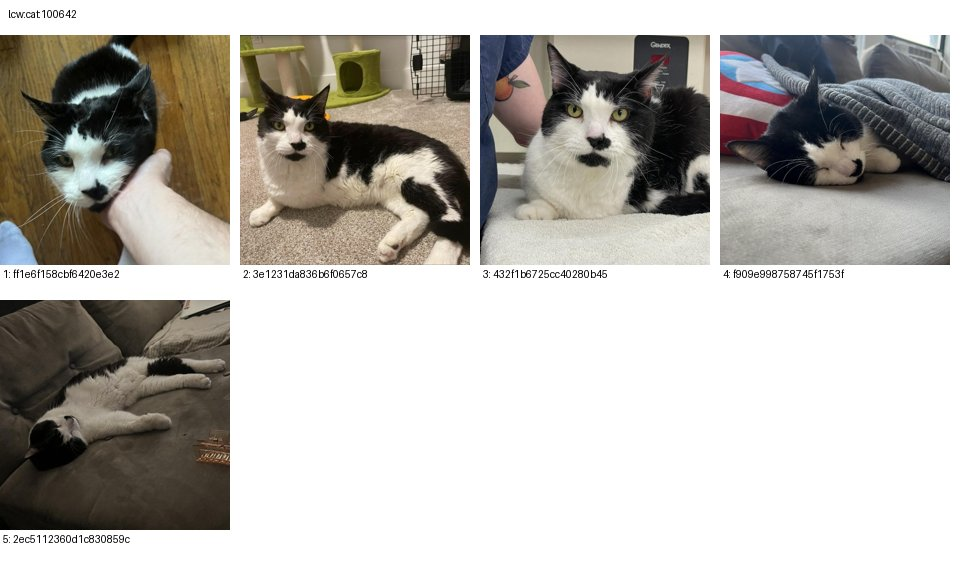

lcw:cat:22124


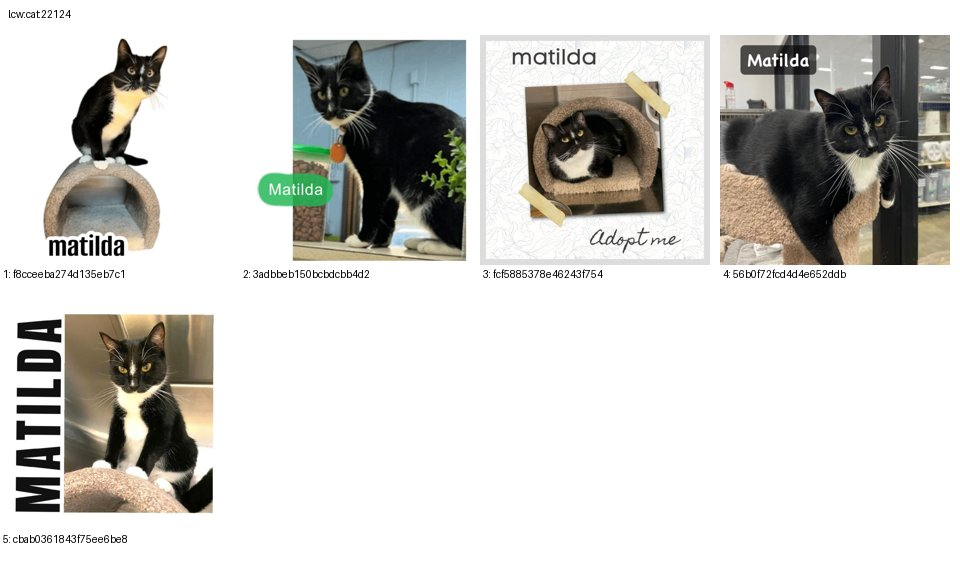

lcw:cat:16911


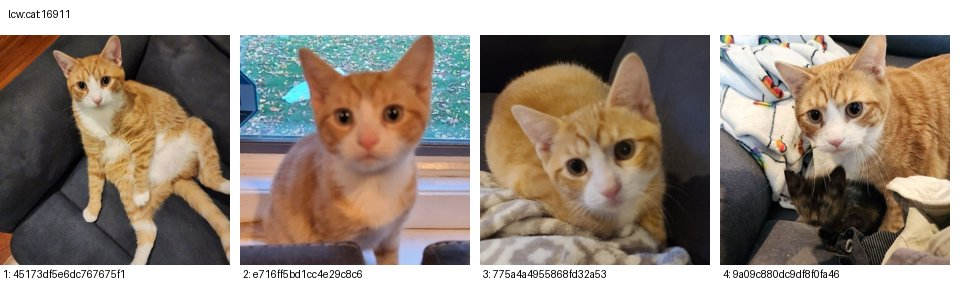

lcw:cat:128764


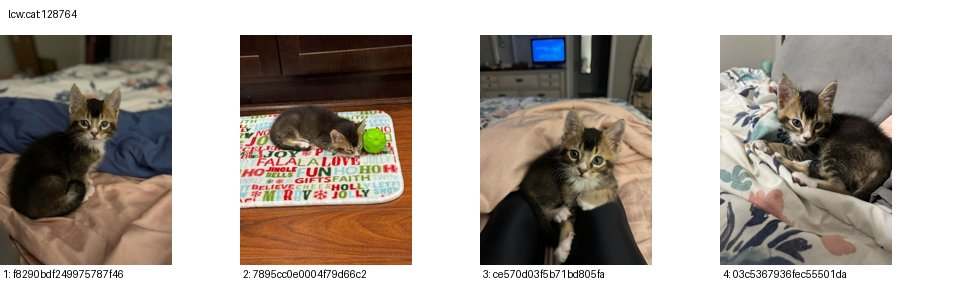

dogs-world:dog:71df0b2177aa434a


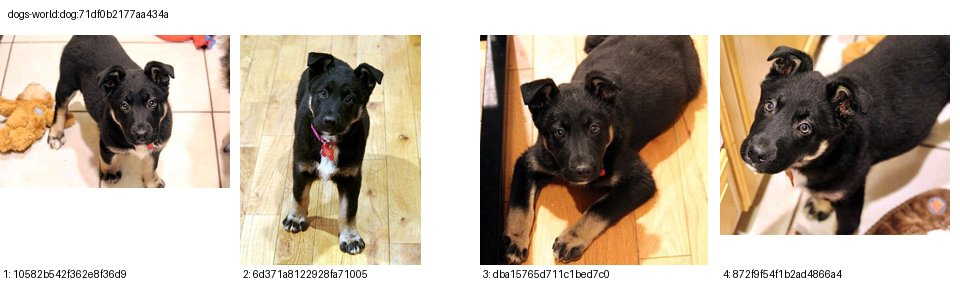

dogs-world:dog:cfbe997212baaf27


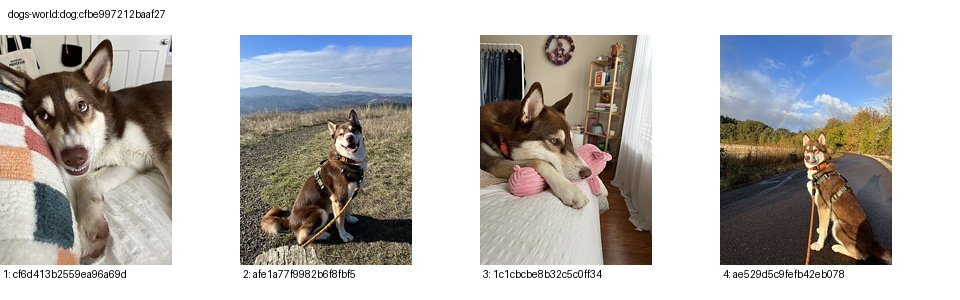

dogs-world:dog:ecebf8e998beb700


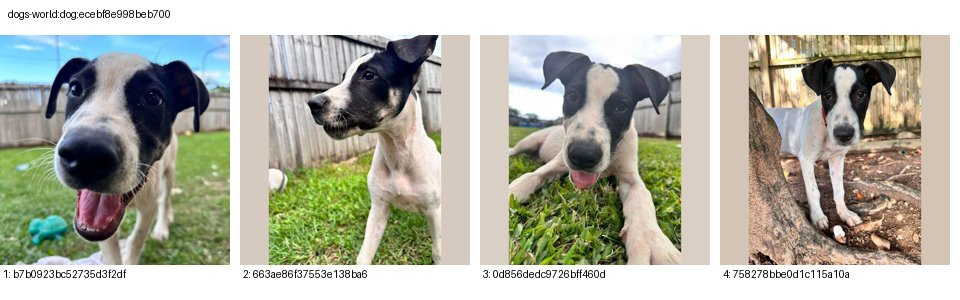

dogs-world:dog:ca70a9c19225238f


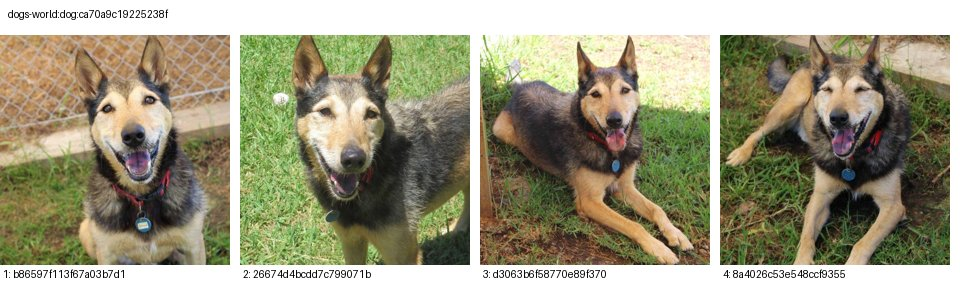

In [9]:
sample = json.loads((prepared.root / "visual-sample.json").read_text())
for item in sample["sample"]:
    print(item["animal"])
    display(Image(filename=str(prepared.root / item["sheet"])))


## 6. Publicación versionada en Hugging Face

La publicación está desactivada por defecto. Al activar `PUBLISH_TO_HF`, se sube la versión preparada al repositorio privado `pettrace-training`, separado de `pettrace-reid`. Se incluyen las imágenes retenidas y el inventario verificado; no se suben extracciones completas, cachés ni credenciales.

La etiqueta `v1` se vincula al commit publicado y no se sobrescribe con otro dataset. Los experimentos pueden fijar commit y fingerprint para reproducir exactamente la muestra. Esta etapa no publica experimentos ni modelos en MLflow.


In [10]:
release = None
if PUBLISH_TO_HF:
    configure_access(names=("HF_TOKEN",))
    release = publish_training(prepared.root, repo_id=TRAINING_REPO, version=DATASET_VERSION)
    (OUTPUT_ROOT / f"{DATASET_VERSION}-hub-release.json").write_text(json.dumps(release, indent=2))
    print(json.dumps(release, indent=2))
else:
    print("Versión local lista. PUBLISH_TO_HF=False: no se publicó en Hugging Face.")


Versión local lista. PUBLISH_TO_HF=False: no se publicó en Hugging Face.


## 7. Consumo desde E3 y futuros experimentos

Los experimentos consumen la versión preparada y registran su fingerprint. Localmente puede usarse el archivo `v1.json` de `datasets/build/pettrace-training`. Si la versión se publica en HF, `load_training` resuelve la referencia una vez y descarga por commit antes de validar todos los hashes.

`pettrace-reid@v4` mantiene su función de evaluación privada. El dataset de entrenamiento tiene sus propias versiones; la publicación de sus datos no activa la publicación de modelos o resultados.


In [11]:
print("E3_PREPARED_DATASET =", version_path)
if release:
    print(json.dumps({
        "HF_TRAINING_DATASET_REPO": release["repo"],
        "HF_TRAINING_DATASET_VERSION": release["version"],
        "HF_TRAINING_DATASET_REVISION": release["commit"],
        "HF_TRAINING_DATASET_FINGERPRINT": release["fingerprint"],
    }, indent=2))


E3_PREPARED_DATASET = /content/datasets/build/pettrace-training/v1.json
